# Support Vector Machine (SVM) - Breast Cancer Classification

## Objective
The objective of this project is to build a Support Vector Machine (SVM) classifier to predict whether a breast tumor is malignant or benign using the Breast Cancer Wisconsin dataset available in Scikit-learn.

## Dataset
- Source: Scikit-learn (`load_breast_cancer`)
- Number of Samples: 569
- Number of Features: 30
- Target Classes:
  - 0 → Malignant
  - 1 → Benign

## Workflow

1. Import Libraries
2. Load Dataset
3. Exploratory Data Analysis
4. Data Preprocessing
5. Feature Scaling
6. Train-Test Split
7. Train Baseline SVM
8. Evaluate Model
9. Hyperparameter Tuning
10. Compare Results
11. Key Learnings

So our model will answer:

"Given these 30 measurements of a tumor, is it malignant or benign?"

This makes it a supervised binary classification problem.

# imports

In [2]:
# Data Manipulation
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn Dataset
from sklearn.datasets import load_breast_cancer

In [4]:
# LOAD the dataset

# Load the Breast Cancer Dataset
data = load_breast_cancer()


In [5]:
type(data) # Bunch is a dictionary with attribute-style access.

sklearn.utils.Bunch

In [7]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [8]:
data.feature_names

array(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error',
       'fractal dimension error', 'worst radius', 'worst texture',
       'worst perimeter', 'worst area', 'worst smoothness',
       'worst compactness', 'worst concavity', 'worst concave points',
       'worst symmetry', 'worst fractal dimension'], dtype='<U23')

In [9]:
data.target_names

array(['malignant', 'benign'], dtype='<U9')

In [10]:
# shape of target
data.data.shape

(569, 30)

In [11]:
# shape of features
data.target.shape

(569,)

In [13]:
# convert to df
df = pd.DataFrame(data.data,columns = data.feature_names)
df['target'] = data.target

In [14]:
df.head(5)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [15]:
df.shape

(569, 31)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

##### Observe

569 rows
31 columns
No missing values
All features are numeric

In [19]:
# Summary statistics
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [20]:
# Missing values
df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [21]:
# Target distribution : The dataset is slightly imbalanced
df["target"].value_counts()

1    357
0    212
Name: target, dtype: int64

Why do you always check for missing values before training a model?

Missing values can cause many machine learning algorithms to fail or produce unreliable results. Checking for them early helps determine whether preprocessing techniques like imputation are required.

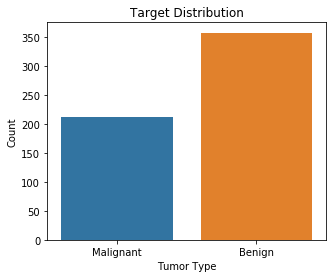

In [24]:
# Visualize the Target Distribution

plt.figure(figsize=(5, 4))

sns.countplot(x=df["target"].map({0: "Malignant", 1: "Benign"}))

plt.title("Target Distribution")
plt.xlabel("Tumor Type")
plt.ylabel("Count")

plt.show()

#### Train-test split

In [25]:
from sklearn.model_selection import train_test_split

In [26]:
X = df.drop("target", axis=1)
y = df["target"]

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

Why stratify=y?

Our dataset is slightly imbalanced:

Benign ≈ 63%
Malignant ≈ 37%

Using stratify=y ensures that both the training and test sets maintain approximately the same class proportions.

Without stratification, you could accidentally end up with a test set containing disproportionately more benign or malignant samples.

#### Spply standard scaler

In [29]:
from sklearn.preprocessing import StandardScaler

In [30]:
scaler = StandardScaler()

In [31]:
X_train_scaled = scaler.fit_transform(X_train)

In [32]:
X_test_scaled = scaler.transform(X_test)

Why fit_transform() on training and only transform() on testing?

This is one of the most important preprocessing interview questions.

fit() learns the mean and standard deviation from the training data.
transform() uses those learned values to scale data.

If you call fit_transform() on the test set, the model gains information from data it shouldn't have seen.

### Import SVM

In [33]:
from sklearn.svm import SVC

Why SVC?

Scikit-learn provides:

SVC → Classification
SVR → Regression

Since we're solving a classification problem, we use SVC.

In [34]:
# Create the model
svm_model = SVC(random_state=42)

In [35]:
# Train the model
svm_model.fit(X_train_scaled, y_train)

SVC(random_state=42)

In [36]:
y_pred = svm_model.predict(X_test_scaled)

In [37]:
# Predictions

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [38]:
cm = confusion_matrix(y_test, y_pred)

cm

array([[41,  1],
       [ 1, 71]])

Which error is more critical in this project?

From a medical perspective, predicting a malignant tumor as benign is generally the more critical mistake because it could delay diagnosis and treatment. Predicting a benign tumor as malignant may lead to unnecessary tests, but it is usually less risky than missing a cancer diagnosis.

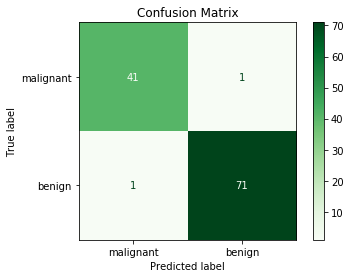

In [43]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot(cmap="Greens")
plt.title("Confusion Matrix")
plt.show()

In [44]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9824561403508771


In [45]:
print(classification_report(y_test, y_pred, target_names=data.target_names))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



#### always establish a baseline, then validate improvements through tuning

the baseline model already performs exceptionally well with an accuracy of about 98.25% and an F1 score close to 0.98–0.99 for both classes. However, I would still perform hyperparameter tuning to check whether the model can be improved further or whether the default parameters are already close to optimal.

Reasons for good baseline model:

The Breast Cancer dataset is relatively clean.
The features contain strong predictive information.
We applied StandardScaler, which is crucial for SVM.
The default RBF kernel is well-suited for many non-linear classification problems.

#### Hyperparameter Tuning

In [46]:
from sklearn.model_selection import GridSearchCV

In [48]:
# Define the param grid

param_grid = {
    "C": [0.1, 1, 10, 100], # C controls the trade-off between margin size and training errors.
    "gamma": [1, 0.1, 0.01, "scale"], # Gamma controls the influence of individual training samples.
    "kernel": ["linear", "rbf"] # Kernel lets us compare a linear boundary against the non-linear RBF boundary.
}

In [49]:
# Let's create gridsearchcv

grid_search = GridSearchCV(
    estimator=SVC(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1,
    verbose=1
)

In [50]:
# fit the grid search cv

grid_search.fit(X_train_scaled, y_train)


Fitting 5 folds for each of 32 candidates, totalling 160 fits


GridSearchCV(cv=5, estimator=SVC(random_state=42), n_jobs=-1,
             param_grid={'C': [0.1, 1, 10, 100],
                         'gamma': [1, 0.1, 0.01, 'scale'],
                         'kernel': ['linear', 'rbf']},
             scoring='f1_weighted', verbose=1)

In [52]:
grid_search.best_params_

{'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}

In [53]:
grid_search.best_score_

0.9800989707326607

In [54]:
best_svm = grid_search.best_estimator_

In [55]:
y_pred_best = best_svm.predict(X_test_scaled)

In [56]:
cm = confusion_matrix(y_test, y_pred_best)

print(cm)

print()

print(classification_report(
    y_test,
    y_pred_best,
    target_names=data.target_names
))

print()

print("Accuracy:", accuracy_score(y_test, y_pred_best))

[[41  1]
 [ 1 71]]

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Accuracy: 0.9824561403508771


#### You performed hyperparameter tuning, but your test accuracy didn't improve. Why?


The baseline SVM already performed extremely well on this dataset. Hyperparameter tuning identified a slightly different parameter combination that performed best during cross-validation, but on the unseen test set, the performance remained the same. This indicates that the default model was already close to optimal and that further tuning did not provide a meaningful gain.

In [57]:
# Comparing the baseline and tuned model
comparison = pd.DataFrame({
    "Model": ["Baseline SVM", "Tuned SVM"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_best)
    ]
})

comparison

,Model,Accuracy
0,Baseline SVM,0.982456
1,Tuned SVM,0.982456


## Conclusion

- Successfully built a baseline Support Vector Machine classifier for breast cancer classification.
- Applied StandardScaler before training because SVM is sensitive to feature scales.
- Achieved an accuracy of 98.25% using the default SVM model.
- Performed hyperparameter tuning using GridSearchCV.
- The tuned model selected:
  - Kernel: RBF
  - C: 10
  - Gamma: 0.01
- The tuned model produced similar performance to the baseline, indicating that the default parameters were already close to optimal for this dataset.